# 00 - Grid

This notebook makes the 1 km grid for our pilot area.
Every dataset uses this grid, so we can merge all the data at the end.

Output: `data/processed/grid_1km.csv` (560 cells)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Our area (from pilot_area.md) - do not change
W, S, E, N = 30.70, 31.05, 30.91, 31.30      # West, South, East, North
LAT_C, LON_C = 31.175, 30.805                # center point
START_YEAR, END_YEAR = 2016, 2024            # full years for the final tables

# Safety check: latitude starts with 31, longitude starts with 30
assert 31 <= S < N < 32, "Latitude is wrong. Did you swap lat and lon?"
assert 30 <= W < E < 31, "Longitude is wrong. Did you swap lat and lon?"
print("Area OK")

Area OK


## Step 1 - Corners of the area in meters

Our area is in degrees (lat, lon). A 1 km cell needs meters.
So we change the 4 corners to UTM zone 36N (EPSG:32636), which uses meters.

In [ ]:
%pip install numpy pandas matplotlib pyproj

In [4]:
from pyproj import Transformer

CELL = 1000  # 1 km in meters
to_utm = Transformer.from_crs("EPSG:4326", "EPSG:32636", always_xy=True)
to_ll  = Transformer.from_crs("EPSG:32636", "EPSG:4326", always_xy=True)

xs, ys = to_utm.transform([W, E, E, W], [S, S, N, N])
x0 = np.floor(min(xs) / CELL) * CELL
x1 = np.ceil(max(xs) / CELL) * CELL
y0 = np.floor(min(ys) / CELL) * CELL
y1 = np.ceil(max(ys) / CELL) * CELL
ncols = int((x1 - x0) / CELL)
nrows = int((y1 - y0) / CELL)

print("x:", x0, "to", x1, "| y:", y0, "to", y1)
print("cols:", ncols, "| rows:", nrows)

x: 280000.0 to 302000.0 | y: 3437000.0 to 3466000.0
cols: 22 | rows: 29


## Step 2 - Make all the cells

We make one row for every 1 km cell in the rectangle.
Row 0 is the north. For each cell we save its 4 edges in meters and its center (in meters and in lat / lon).

In [5]:
rows, cols = np.meshgrid(np.arange(nrows), np.arange(ncols), indexing="ij")
rows, cols = rows.ravel(), cols.ravel()

x_min = x0 + cols * CELL
y_max = y1 - rows * CELL
x_c, y_c = x_min + CELL / 2, y_max - CELL / 2
lon, lat = to_ll.transform(x_c, y_c)

grid = pd.DataFrame({
    "row": rows, "col": cols,
    "x_min_m": x_min, "x_max_m": x_min + CELL,
    "y_min_m": y_max - CELL, "y_max_m": y_max,
    "x_m": x_c, "y_m": y_c,
    "lat": np.round(lat, 6), "lon": np.round(lon, 6),
})

print("All cells in the rectangle:", len(grid))
grid.head()

All cells in the rectangle: 638


,row,col,x_min_m,x_max_m,y_min_m,y_max_m,x_m,y_m,lat,lon
0,0,0,280000.0,281000.0,3465000.0,3466000.0,280500.0,3465500.0,31.303191,30.693712
1,0,1,281000.0,282000.0,3465000.0,3466000.0,281500.0,3465500.0,31.303380,30.704212
2,0,2,282000.0,283000.0,3465000.0,3466000.0,282500.0,3465500.0,31.303567,30.714712
3,0,3,283000.0,284000.0,3465000.0,3466000.0,283500.0,3465500.0,31.303753,30.725212
4,0,4,284000.0,285000.0,3465000.0,3466000.0,284500.0,3465500.0,31.303939,30.735712


## Step 3 - Keep only the cells inside our area

The rectangle in meters is a bit bigger than our area in degrees.
We keep a cell only if its center is inside our area.
Then we give each cell a number: cell_id from 1 to 560.

In [6]:
inside = grid.lon.between(W, E) & grid.lat.between(S, N)
grid = grid[inside].reset_index(drop=True)
grid.insert(0, "cell_id", np.arange(1, len(grid) + 1))

print("Cells inside our area:", len(grid))
print("lat:", grid.lat.min(), "to", grid.lat.max())
print("lon:", grid.lon.min(), "to", grid.lon.max())

assert len(grid) == 560, "The grid must have 560 cells"
assert grid.lat.between(31, 32).all() and grid.lon.between(30, 31).all()
print("Grid OK")

Cells inside our area: 560
lat: 31.050939 to 31.297776
lon: 30.704431 to 30.909285
Grid OK


## Step 4 - Look at the grid

We plot the center of every cell and the edge of our area.
Cell 1 should be in the north-west. Cell 560 should be in the south-east.

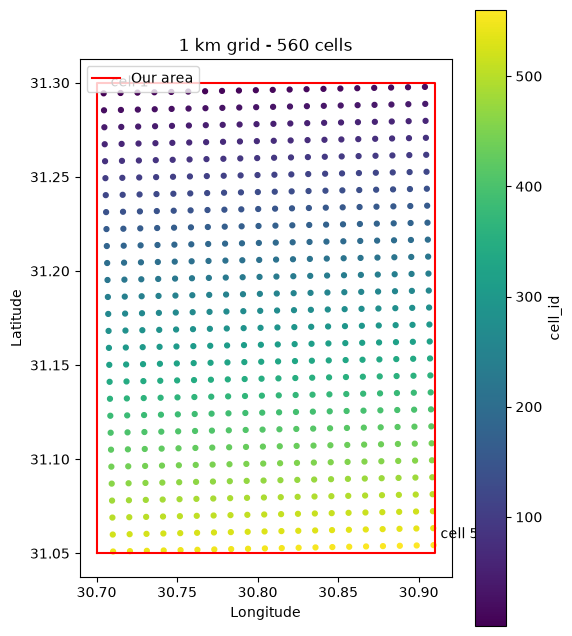

In [7]:
fig, ax = plt.subplots(figsize=(6, 8))
sc = ax.scatter(grid.lon, grid.lat, c=grid.cell_id, s=12, cmap="viridis")
ax.plot([W, E, E, W, W], [S, S, N, N, S], color="red", lw=1.5, label="Our area")

for cid in [1, 560]:
    r = grid[grid.cell_id == cid].iloc[0]
    ax.annotate(f"cell {cid}", (r.lon, r.lat), xytext=(5, 5), textcoords="offset points")

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("1 km grid - 560 cells")
ax.set_aspect(1 / np.cos(np.radians(LAT_C)))   # so the map is not stretched
ax.legend()
plt.colorbar(sc, label="cell_id")
plt.show()

In [8]:
ax.legend(loc="lower left")

In [9]:
grid.to_csv("../data/processed/grid_1km.csv", index=False)

check = pd.read_csv("../data/processed/grid_1km.csv")
print("Saved:", len(check), "rows,", check.shape[1], "columns")
print(check.columns.tolist())

Saved: 560 rows, 11 columns
['cell_id', 'row', 'col', 'x_min_m', 'x_max_m', 'y_min_m', 'y_max_m', 'x_m', 'y_m', 'lat', 'lon']


## Conclusion

- The grid has 560 cells of 1 km x 1 km, in UTM zone 36N (EPSG:32636).
- All cell centers are inside our area (lat 31.05 to 31.30, lon 30.70 to 30.91).
- Cell 1 is in the north-west, cell 560 is in the south-east.
- The rows look a little tilted on the map. This is normal: the UTM grid is not exactly aligned with lat / lon lines.
- Output: `data/processed/grid_1km.csv`. Every dataset must use this file.